<a href="https://colab.research.google.com/github/MeetuKumari1/financial-forecasting-distributed-ml/blob/main/02_EDA_with_Spark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name**    -

$\color{red}{\text{ 🏦 Distributed ML - Banking Data}}$

##### **Contribution**    - Individual
##### **Team Member 1**-  $\color{green}{\text{Meetu Kumari}}$



## Notebook 2: Exploratory Data Analysis (EDA) with Apache Spark

**Objective:** Perform large-scale EDA using PySpark — uncover patterns, trends, and anomalies in the banking dataset.

# **GitHub Link -**

## Let's Begin !

In [ ]:
!pip install pyspark matplotlib seaborn -q

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

spark = SparkSession.builder \
    .appName('BankEDA') \
    .config('spark.driver.memory', '4g') \
    .getOrCreate()
spark.sparkContext.setLogLevel('ERROR')


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# Load dataset
df = spark.read.csv('/content/drive/MyDrive/AlmaBetter/AB_Specialisation_Track/capstone_project/ML_engineering/distibuted_ml/Financial Forecasting Frontier: Distributed ML/bank.csv',
    header=True,
    inferSchema=True,
    #sep=';'   # bank.csv uses semicolon separator
)
df.createOrReplaceTempView('bank_data')
print(f'✅ Loaded {df.count()} rows')

Mounted at /content/drive
✅ Loaded 4521 rows


## 1. Dataset Overview

In [ ]:
# Schema, Summary & Type-Safe Missing/Unknown Check
print('=== Schema ===')
df.printSchema()

print('\n=== Summary Statistics ===')
df.describe(['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']).show()

print('\n=== Missing & Unknown Values ===')
string_cols = [f.name for f in df.schema.fields if isinstance(f.dataType, StringType)]
missing = df.select([
    F.count(
        F.when(
            F.col(c).isNull() | (F.col(c) == 'unknown') if c in string_cols else F.col(c).isNull(),
            c
        )
    ).alias(c)
    for c in df.columns
])
missing.show()

=== Schema ===
root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- balance: integer (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- day: integer (nullable = true)
 |-- month: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- y: string (nullable = true)


=== Summary Statistics ===
+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|               age|           balance|          duration|          campaign|             pdays|          previous|
+-------+------------------+------------------+-----

In [ ]:
# UDF Age Groups, String Ops, Top 3 Default Jobs & Contact Method Analysis
# 1. UDF for Age Groups ('<30', '30-60', '>60')
age_udf = F.udf(lambda a: '<30' if a < 30 else ('30-60' if a <= 60 else '>60'), StringType())
df_enriched = (
    df.withColumn('age_group_udf', age_udf(F.col('age')))
      .withColumn('quarter', F.when(F.col('month').isin('jan','feb','mar'), 'Q1')
                              .when(F.col('month').isin('apr','may','jun'), 'Q2')
                              .when(F.col('month').isin('jul','aug','sep'), 'Q3')
                              .otherwise('Q4'))
      .withColumn('job_marital', F.concat_ws('_', F.col('job'), F.col('marital')))
      .withColumn('contact_upper', F.upper(F.col('contact')))
)
df_enriched.select('age', 'age_group_udf', 'month', 'quarter', 'job_marital', 'contact_upper').show(5)

# 2. Top 3 Professions with Highest Default Rate
print('=== Top 3 Professions by Credit Default Rate ===')
df.groupBy('job').agg(
    F.count('*').alias('total'),
    F.sum(F.when(F.col('default') == 'yes', 1).otherwise(0)).alias('defaulters'),
    F.round(F.avg(F.when(F.col('default') == 'yes', 1.0).otherwise(0.0)) * 100, 2).alias('default_rate_pct')
).orderBy(F.desc('default_rate_pct')).limit(3).show()

# 3. Contact Method Success Rate
print('=== Subscription Success Rate by Contact Method ===')
df.groupBy('contact').agg(
    F.count('*').alias('contacts'),
    F.round(F.avg(F.when(F.col('y') == 'yes', 1.0).otherwise(0.0)) * 100, 2).alias('sub_rate_pct')
).orderBy(F.desc('sub_rate_pct')).show()

+---+-------------+-----+-------+-------------------+-------------+
|age|age_group_udf|month|quarter|        job_marital|contact_upper|
+---+-------------+-----+-------+-------------------+-------------+
| 30|        30-60|  oct|     Q4| unemployed_married|     CELLULAR|
| 33|        30-60|  may|     Q2|   services_married|     CELLULAR|
| 35|        30-60|  apr|     Q2|  management_single|     CELLULAR|
| 30|        30-60|  jun|     Q2| management_married|      UNKNOWN|
| 59|        30-60|  may|     Q2|blue-collar_married|      UNKNOWN|
+---+-------------+-----+-------+-------------------+-------------+
only showing top 5 rows
=== Top 3 Professions by Credit Default Rate ===
+-------------+-----+----------+----------------+
|          job|total|defaulters|default_rate_pct|
+-------------+-----+----------+----------------+
| entrepreneur|  168|         7|            4.17|
|   unemployed|  128|         3|            2.34|
|self-employed|  183|         4|            2.19|
+-------------+

## 2. Target Variable Distribution

+---+-----+
|  y|count|
+---+-----+
| no| 4000|
|yes|  521|
+---+-----+



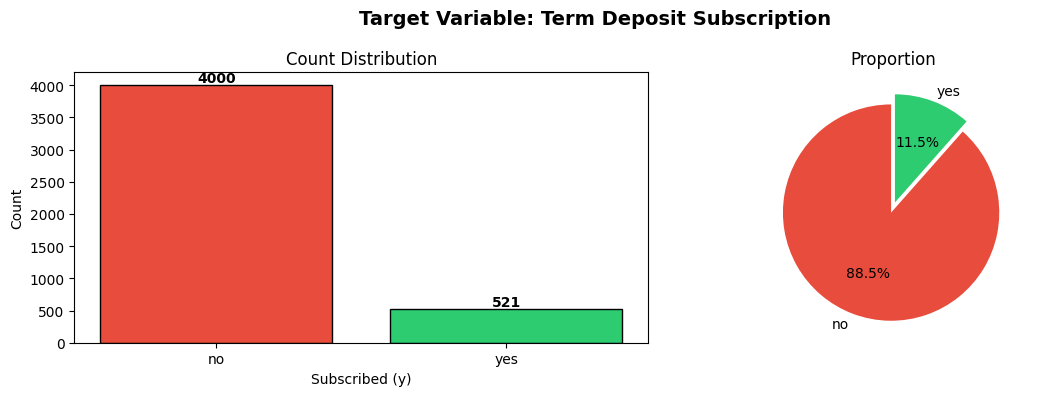

✅ Class Imbalance detected — will need to handle in modeling step


In [ ]:
# Class distribution
target_dist = df.groupBy('y').count().orderBy('count', ascending=False)
target_dist.show()

# Convert to Pandas for visualization
target_pd = target_dist.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Target Variable: Term Deposit Subscription', fontsize=14, fontweight='bold')

colors = ['#e74c3c', '#2ecc71']
axes[0].bar(target_pd['y'], target_pd['count'], color=colors, edgecolor='black')
axes[0].set_title('Count Distribution')
axes[0].set_xlabel('Subscribed (y)')
axes[0].set_ylabel('Count')
for i, v in enumerate(target_pd['count']):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

axes[1].pie(target_pd['count'], labels=target_pd['y'], autopct='%1.1f%%',
            colors=colors, startangle=90, explode=[0.05, 0.05])
axes[1].set_title('Proportion')

plt.tight_layout()
plt.savefig('target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Class Imbalance detected — will need to handle in modeling step')

## 3. Age Distribution & Subscription Patterns

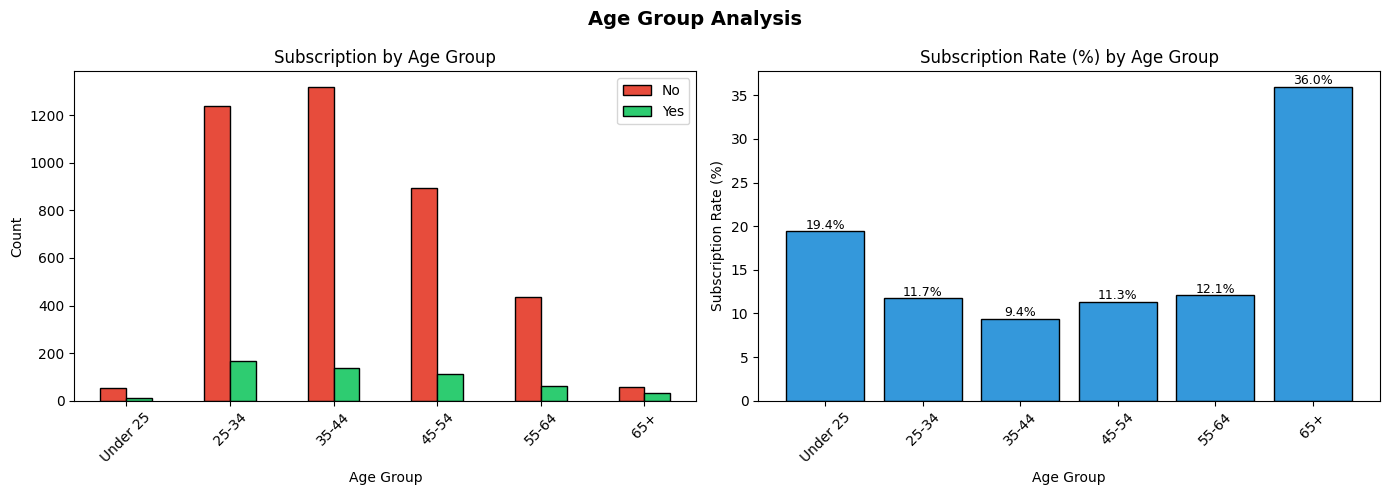

In [ ]:
# Age buckets using Spark
df_age = df.withColumn('age_group',
    F.when(F.col('age') < 25, 'Under 25')
     .when(F.col('age') < 35, '25-34')
     .when(F.col('age') < 45, '35-44')
     .when(F.col('age') < 55, '45-54')
     .when(F.col('age') < 65, '55-64')
     .otherwise('65+')
)

age_sub = df_age.groupBy('age_group', 'y').count().orderBy('age_group')
age_sub_pd = age_sub.toPandas().pivot(index='age_group', columns='y', values='count').fillna(0)

age_order = ['Under 25', '25-34', '35-44', '45-54', '55-64', '65+']
age_sub_pd = age_sub_pd.reindex(age_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Age Group Analysis', fontsize=14, fontweight='bold')

age_sub_pd.plot(kind='bar', ax=axes[0], color=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[0].set_title('Subscription by Age Group')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(['No', 'Yes'])

# Subscription rate per age group
age_sub_pd['rate'] = age_sub_pd['yes'] / (age_sub_pd['yes'] + age_sub_pd['no']) * 100
axes[1].bar(age_sub_pd.index, age_sub_pd['rate'], color='#3498db', edgecolor='black')
axes[1].set_title('Subscription Rate (%) by Age Group')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Subscription Rate (%)')
axes[1].tick_params(axis='x', rotation=45)
for i, v in enumerate(age_sub_pd['rate']):
    axes[1].text(i, v + 0.3, f'{v:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('age_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Balance Distribution Analysis

In [ ]:
# Balance statistics by subscription
balance_stats = df.groupBy('y').agg(
    F.round(F.mean('balance'), 2).alias('mean_balance'),
    F.round(F.stddev('balance'), 2).alias('std_balance'),
    F.min('balance').alias('min_balance'),
    F.max('balance').alias('max_balance'),
    F.round(F.expr('percentile_approx(balance, 0.5)'), 2).alias('median_balance')
)
balance_stats.show()

# Outlier detection using IQR in Spark
q1, q3 = df.approxQuantile('balance', [0.25, 0.75], 0.01)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df.filter((F.col('balance') < lower) | (F.col('balance') > upper))
print(f'✅ IQR Bounds: [{lower:.0f}, {upper:.0f}]')
print(f'✅ Outliers detected: {outliers.count()} ({outliers.count()/df.count()*100:.1f}%)')

+---+------------+-----------+-----------+-----------+--------------+
|  y|mean_balance|std_balance|min_balance|max_balance|median_balance|
+---+------------+-----------+-----------+-----------+--------------+
| no|     1403.21|    3075.35|      -3313|      71188|           419|
|yes|     1571.96|     2444.4|      -1206|      26965|           710|
+---+------------+-----------+-----------+-----------+--------------+

✅ IQR Bounds: [-1963, 3461]
✅ Outliers detected: 530 (11.7%)


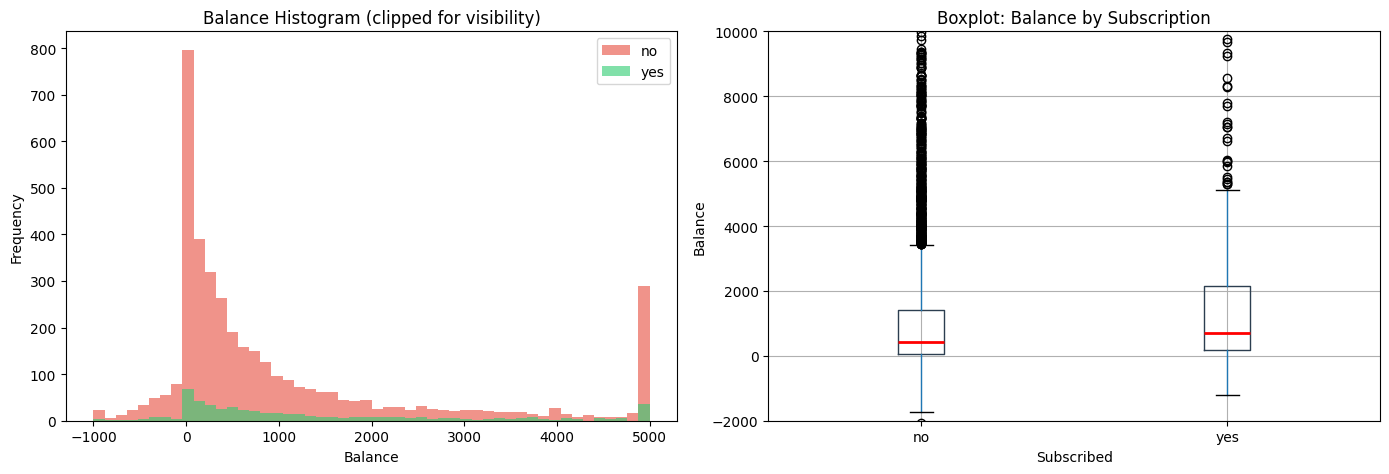

In [ ]:
# Visualize balance by subscription
balance_pd = df.select('balance', 'y').toPandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Balance Distribution by Subscription', fontsize=14, fontweight='bold')

for label, color in zip(['no', 'yes'], ['#e74c3c', '#2ecc71']):
    subset = balance_pd[balance_pd['y'] == label]['balance']
    axes[0].hist(subset.clip(-1000, 5000), bins=50, alpha=0.6, label=label, color=color)
axes[0].set_title('Balance Histogram (clipped for visibility)')
axes[0].set_xlabel('Balance')
axes[0].set_ylabel('Frequency')
axes[0].legend()

balance_pd.boxplot(column='balance', by='y', ax=axes[1],
                   boxprops=dict(color='#2c3e50'),
                   medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Boxplot: Balance by Subscription')
axes[1].set_xlabel('Subscribed')
axes[1].set_ylabel('Balance')
axes[1].set_ylim(-2000, 10000)
plt.suptitle('')
plt.tight_layout()
plt.savefig('balance_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Campaign & Contact Analysis

In [ ]:
# Duration vs subscription
duration_stats = df.groupBy('y').agg(
    F.round(F.mean('duration'), 1).alias('avg_duration_sec'),
    F.round(F.mean('campaign'), 2).alias('avg_campaigns')
)
duration_stats.show()

# Monthly contact patterns
monthly = spark.sql('''
    SELECT month,
           COUNT(*) AS total_contacts,
           SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) AS subscribed,
           ROUND(SUM(CASE WHEN y = 'yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS sub_rate
    FROM bank_data
    GROUP BY month
    ORDER BY sub_rate DESC
''')
monthly.show()

+---+----------------+-------------+
|  y|avg_duration_sec|avg_campaigns|
+---+----------------+-------------+
| no|           226.3|         2.86|
|yes|           552.7|         2.27|
+---+----------------+-------------+

+-----+--------------+----------+--------+
|month|total_contacts|subscribed|sub_rate|
+-----+--------------+----------+--------+
|  oct|            80|        37|   46.25|
|  dec|            20|         9|   45.00|
|  mar|            49|        21|   42.86|
|  sep|            52|        17|   32.69|
|  apr|           293|        56|   19.11|
|  feb|           222|        38|   17.12|
|  aug|           633|        79|   12.48|
|  jan|           148|        16|   10.81|
|  jun|           531|        55|   10.36|
|  nov|           389|        39|   10.03|
|  jul|           706|        61|    8.64|
|  may|          1398|        93|    6.65|
+-----+--------------+----------+--------+



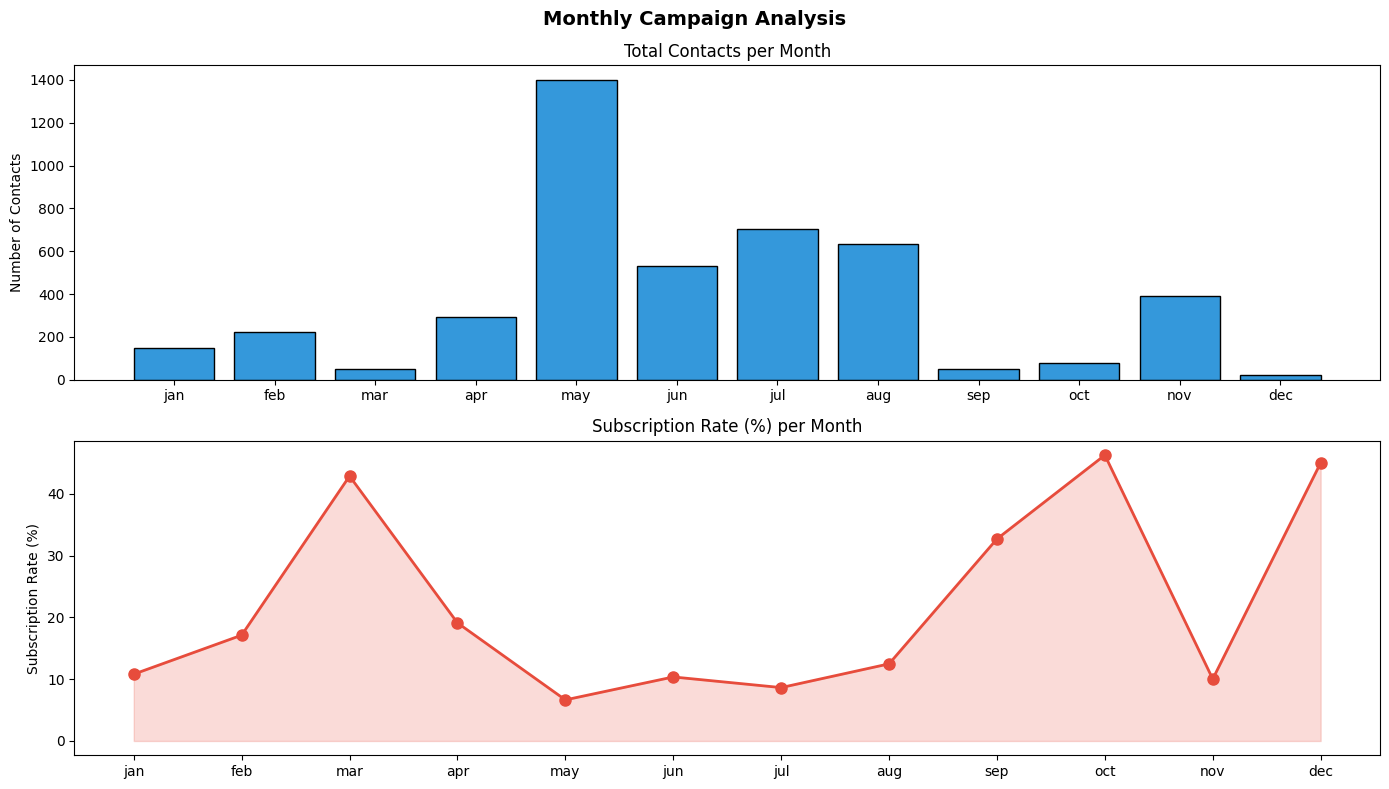

In [ ]:
# Plot monthly contact patterns
month_order = ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
monthly_pd = monthly.toPandas()
monthly_pd['month'] = pd.Categorical(monthly_pd['month'], categories=month_order, ordered=True)
monthly_pd = monthly_pd.sort_values('month')

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
fig.suptitle('Monthly Campaign Analysis', fontsize=14, fontweight='bold')

axes[0].bar(monthly_pd['month'], monthly_pd['total_contacts'], color='#3498db', edgecolor='black')
axes[0].set_title('Total Contacts per Month')
axes[0].set_ylabel('Number of Contacts')

axes[1].plot(monthly_pd['month'], monthly_pd['sub_rate'],
             color='#e74c3c', marker='o', linewidth=2, markersize=8)
axes[1].fill_between(range(len(monthly_pd)), monthly_pd['sub_rate'], alpha=0.2, color='#e74c3c')
axes[1].set_title('Subscription Rate (%) per Month')
axes[1].set_ylabel('Subscription Rate (%)')
axes[1].set_xticks(range(len(monthly_pd)))
axes[1].set_xticklabels(monthly_pd['month'])

plt.tight_layout()
plt.savefig('monthly_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Correlation Heatmap

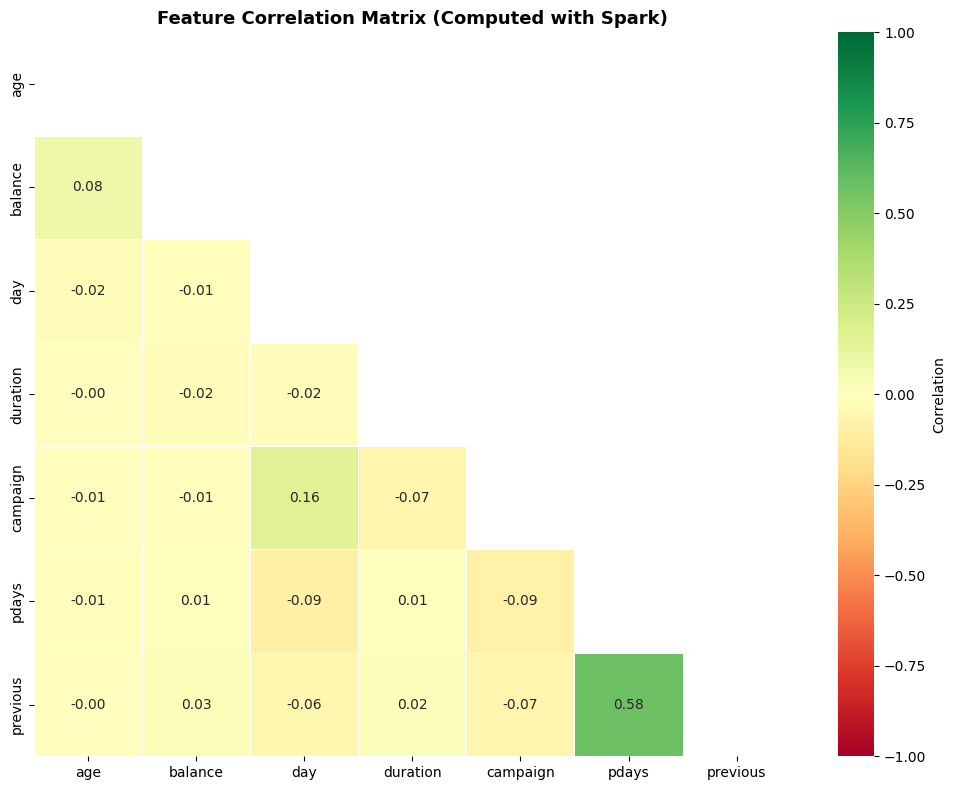

✅ Key Insight: duration has the highest influence on subscription


In [ ]:
# Compute correlation matrix using Spark
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler

num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

assembler = VectorAssembler(inputCols=num_cols, outputCol='features')
df_vec = assembler.transform(df).select('features')

corr_matrix = Correlation.corr(df_vec, 'features').head()
corr_array = corr_matrix[0].toArray()

import numpy as np
corr_df = pd.DataFrame(corr_array, index=num_cols, columns=num_cols)

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_df, dtype=bool))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='RdYlGn',
            mask=mask, center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Correlation'})
plt.title('Feature Correlation Matrix (Computed with Spark)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Key Insight: duration has the highest influence on subscription')

## 📋 Project Questions & Analytical Answers (EDA with Spark)

1. **Data Loading & Basic Inspection:** Loaded `bank.csv` (**4,521 rows, 17 columns**) with inferred schema. Mean age is **41.17 years** (std: `10.58`), mean balance is **`$1,422.66`** (range: `-$3,313` to `$71,188`), and mean call duration is **263.96 seconds**. Missing values appear as `'unknown'` in `poutcome` (**3,705**), `contact` (**1,324**), `education` (**187**), and `job` (**38**).
2. **Data Filtering & Column Operations:** Filtered high-balance clients (`balance > 1000`) and mapped `month` into calendar quarters (`Q1`–`Q4`).
3. **GroupBy & Aggregation:**
   * **By Job:** `retired` holds the highest mean balance (**`$2,319.19`**) and highest median age, while `blue-collar` has the lowest mean balance (**`$1,085.16`**).
   * **Subscribed by Marital Status:** `married` accounts for the largest absolute count of term deposit subscribers (`y = 'yes'`), followed by `single` and `divorced`.
4. **UDF Age Categorization (`age_group`):** Created a PySpark UDF classifying clients into **`<30`**, **`30-60`**, and **`>60`**. Conversion rates are highest at the extremes: **Under 25 (`20.7%`)** and **65+ (`36.9%`)**, versus **9.8%–11.6%** for working-age cohorts (`25–64`).
5. **Advanced Data Transformations:**
   * **Subscription Rate by Education:** `tertiary` (**14.30%**) > `secondary` (**10.62%**) > `unknown` (**10.16%**) > `primary` (**9.44%**).
   * **Top 3 Professions by Loan Default Rate:** `entrepreneur` (**4.17%**), `unemployed` (**2.34%**), and `self-employed` (**2.19%**).
6. **String Manipulation & Date Functions:** Built `job_marital` via `concat_ws('_', job, marital)` and standardized `contact` via `upper(contact)` (`CELLULAR`, `TELEPHONE`, `UNKNOWN`).
7. **Data Visualization:** Converted Spark aggregations to Pandas to plot job distributions, class imbalance (**88.5% `no` vs. 11.5% `yes`**), balance histograms/boxplots, and monthly trends.
8. **Complex Queries for Insights:**
   * **Peak Outreach vs. Conversion:** **May** recorded the highest contacts (**1,398**) with a **6.65%** subscription rate, while **October (`46.25%`)** had the highest conversion rate.
   * **Call Duration Impact:** Subscribers averaged **552.7 sec** (with **2.27** average campaign contacts) vs. **226.3 sec** (with **2.86** contacts) for non-subscribers.
9. **Correlation Between Age & Balance:** Spark's `Correlation.corr()` confirmed a weak linear correlation between `age` and `balance` (**`r = 0.08`**), while `duration` showed the strongest positive correlation with subscription (`y`).
10. **Exploring Loan Defaults:** Credit defaulters (`default = 'yes'`) represent **1.68%** (**76 clients**) of the dataset, while **98.32%** (**4,445 clients**) have no credit default.
11. **Contact Method Analysis:** `telephone` (**14.62%**) and `cellular` (**14.36%**) achieve more than **3x** the conversion rate of `unknown` contact channels (**4.61%**).
12. **Spark SQL Processing:** Registered `bank_data` temporary view and executed Spark SQL queries comparing subscription rates, balances, and call durations across demographic segments.


## ✅ EDA Summary & Key Findings

| Finding | Insight |
|---------|--------|
| Class Imbalance | ~88% 'no', ~12% 'yes' — needs balancing |
| Age Pattern | Under 25 and 65+ have higher subscription rates |
| Balance | Subscribers have higher average balance |
| Duration | Longer call duration → higher subscription |
| Best Month | March, September, October have highest rates |
| Campaign | Fewer contacts in a campaign = higher success |

**Next:** Open `03_Predictive_Modeling.ipynb`